# Adaptive step-size forward Euler for a stiff ODE

Companion notebook for the adaptive step-size selection section of `Lec13.tex`. We solve the stiff ODE
`eq:stiff-ODE-example` from `Lec10.tex`,
$$
\frac{du}{dt} = f(t, u) = -100\,(u - \sin(t)), \qquad u(0) = 1,
$$
with forward Euler, $u_{n+1} = u_n + \Delta t_n f(t_n, u_n)$, but now the step size $\Delta t_n$ changes from step to step.

**Error estimator.** The local truncation error of forward Euler is
$\frac{\Delta t^2}{2} u''(t_n) + \mathcal{O}(\Delta t^3)$. Since $u'' = \frac{d}{dt} f(t, u(t))$, we can estimate it with a
finite difference of $f$ over the step we just took:
$$
E_n = \frac{\Delta t_n}{2}\, \big| f(t_{n+1}, u_{n+1}) - f(t_n, u_n) \big| \approx \frac{\Delta t_n^2}{2} |u''(t_n)|.
$$
This is the difference between a forward Euler step and a (second order) Heun step, and it costs no extra function
evaluations since $f(t_{n+1}, u_{n+1})$ is needed for the next step anyway.

**Step-size control.** Given a tolerance $\varepsilon$:
- if $E_n \le \varepsilon$ we accept the step, otherwise we reject it and retry from $t_n$;
- in either case the next step size is $\Delta t_{\rm new} = \Delta t_n \cdot \min\big(2, \max(0.2,\ 0.9 \sqrt{\varepsilon / E_n})\big)$.

The exponent $1/2$ comes from $E_n \propto \Delta t_n^2$, the factor $0.9$ is a safety factor, and the bounds $0.2$ and $2$
keep the step size from changing too abruptly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def f(t, u):
    return -100 * (u - np.sin(t))


def adaptive_forward_euler(f, u0, T, tol, dt0=1e-3):
    t, u = 0.0, u0
    ts, us = [t], [u]
    dt = dt0
    n_rejected = 0
    f_n = f(t, u)
    while t < T:
        dt = min(dt, T - t)
        u_new = u + dt * f_n
        f_new = f(t + dt, u_new)
        err = 0.5 * dt * abs(f_new - f_n)  # estimate of the local truncation error

        if err <= tol:  # accept the step
            t, u, f_n = t + dt, u_new, f_new
            ts.append(t)
            us.append(u)
        else:
            n_rejected += 1

        # update the step size, whether or not the step was accepted
        factor = 0.9 * np.sqrt(tol / err) if err > 0 else 2.0
        dt = dt * min(2.0, max(0.2, factor))
    return np.array(ts), np.array(us), n_rejected

In [3]:
T = 3.0
tol = 1e-3
t, u, n_rejected = adaptive_forward_euler(f, 1.0, T, tol)
dt = np.diff(t)

print(f"accepted steps: {len(dt)}, rejected steps: {n_rejected}")
print(f"smallest step: {dt.min():.2e}, largest step: {dt.max():.2e}")
print(f"a uniform step of {dt.min():.2e} would need {int(np.ceil(T / dt.min()))} steps")

accepted steps: 194, rejected steps: 61
smallest step: 4.00e-04, largest step: 5.89e-02
a uniform step of 4.00e-04 would need 7491 steps


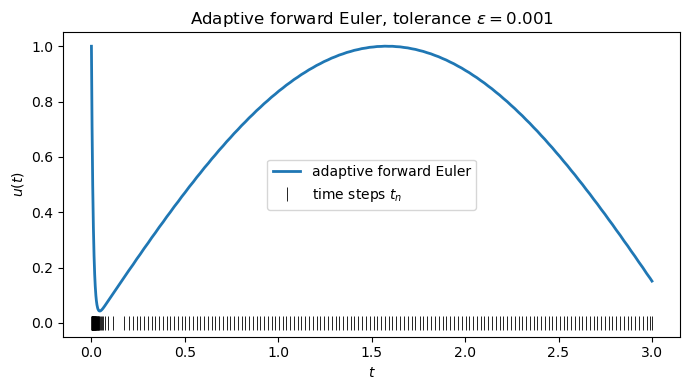

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t, u, "-", linewidth=2, label="adaptive forward Euler")
# one tick mark on the time axis at each time step t_n
ax.plot(t, np.zeros_like(t), "|", color="k", markersize=10, markeredgewidth=0.6, label=r"time steps $t_n$")
ax.set_xlabel(r"$t$")
ax.set_ylabel(r"$u(t)$")
ax.set_title(rf"Adaptive forward Euler, tolerance $\varepsilon = {tol:g}$")
ax.legend()
fig.tight_layout()
fig.savefig("adaptive_forward_euler.png", dpi=300, bbox_inches="tight")
plt.show()

The tick marks are densely packed during the fast initial transient, where $|u''|$ is large, and spread out once the
solution follows the slowly varying sinusoid. Note that the step size does not grow indefinitely: forward Euler is only
stable for $\Delta t < 2/100 = 0.02$, and whenever the controller pushes $\Delta t$ past this limit the solution starts
to oscillate, $f$ jumps between steps, the error estimate grows, and the step size is cut back.